Recommendation systems are a collection of algorithms used to recommend items to users based on information taken from the user. These systems have become ubiquitous, and can be commonly seen in online stores, movies databases and job finders. In this notebook, we will explore Content-based recommendation systems and implement one using Python, **pandas** and **scikit-learn**.

This version uses the current pandas 2.x/3.x API and a few modern content-based techniques:
* **Vectorized one-hot encoding** instead of looping over rows
* **Mean-centered ratings** so the movies a user disliked count *against* their genres
* **IDF weighting** so rare genres (e.g. *Film-Noir*) count more than very common ones (e.g. *Drama*)
* **Cosine similarity** to score every movie against the user profile
* Already-watched movies are excluded, and ties are broken by popularity

First, let's get all of the imports out of the way:

In [1]:
# Dataframe manipulation library
import pandas as pd
# Numerical arrays (used for the IDF weights)
import numpy as np
# Plotting the user profile
import matplotlib.pyplot as plt
# Builds file paths that work on Windows, macOS and Linux
from pathlib import Path

# scikit-learn tools for the content-based model:
# MultiLabelBinarizer -> one-hot encodes a column of lists (our genres)
# cosine_similarity   -> measures how close each movie is to the user profile
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity

Now let's load the data. Both files live in this lesson's `data/` folder: **movies.csv** and **ratings_sample.csv.gz** — the ratings compressed with gzip, which pandas reads without any extra step. Using `pathlib.Path` and the `/` operator keeps the path readable and avoids the backslash problems of plain Windows strings.

In [2]:
DATA_DIR = Path("data")

movies_df = pd.read_csv(DATA_DIR / "movies.csv")
# The ratings file is gzip-compressed (26 MB instead of 102 MB); pandas reads it directly
ratings_df = pd.read_csv(DATA_DIR / "ratings_sample.csv.gz")
movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Let's also move the year out of the **title** column into a new **year** column.

The order matters: we must **extract the year first** (while it's still in the title) and only then remove it from the title. The original version did it the other way round, so the year was already gone and `movies_df.year` didn't exist yet (`AttributeError`). All regular expressions are written as raw strings (`r'...'`) so Python doesn't treat `\d` and `\(` as escape sequences (the `SyntaxWarning`).

In [3]:
# 1) Extract the 4-digit year between parentheses into a new 'year' column.
#    The capture group (\d{4}) keeps only the digits. We include the parentheses in the
#    pattern so we don't grab numbers that are part of a title, like '2001: A Space Odyssey'.
movies_df['year'] = movies_df['title'].str.extract(r'\((\d{4})\)', expand=False)

# Convert to a nullable integer type (Int64) so missing years stay as <NA> instead of breaking the column
movies_df['year'] = pd.to_numeric(movies_df['year'], errors='coerce').astype('Int64')

# 2) Now remove the '(YYYY)' part from the title. regex=True must be explicit in modern pandas.
movies_df['title'] = movies_df['title'].str.replace(r'\(\d{4}\)', '', regex=True)

# 3) Strip any leftover whitespace at the ends. The vectorized .str.strip() replaces .apply(lambda x: x.strip())
movies_df['title'] = movies_df['title'].str.strip()
movies_df.head()

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji,Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men,Comedy|Romance,1995
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II,Comedy,1995


With that, let's also split the values in the **Genres** column into a **list of Genres** to simplify for future use. This can be achieved by applying Python's split string function on the correct column.

In [4]:
# Every genre is separated by a | so we simply have to call the split function on |
movies_df['genres'] = movies_df['genres'].str.split('|')
movies_df.head()

,movieId,title,genres,year
0,1,Toy Story,"[Adventure, Animation, Children, Comedy, Fantasy]",1995
1,2,Jumanji,"[Adventure, Children, Fantasy]",1995
2,3,Grumpier Old Men,"[Comedy, Romance]",1995
3,4,Waiting to Exhale,"[Comedy, Drama, Romance]",1995
4,5,Father of the Bride Part II,[Comedy],1995


Since keeping genres in a list format isn't optimal for the content-based recommendation system technique, we will use the One Hot Encoding technique to convert the list of genres to a vector where each column corresponds to one possible value of the feature. In this case, we store every different genre in columns that contain either 1 or 0. 1 shows that a movie has that genre and 0 shows that it doesn't.

Instead of looping over every row with `iterrows()` (very slow on 34,000 movies), we use scikit-learn's `MultiLabelBinarizer`, which is built exactly for a column of lists and does it in one vectorized step. It also avoids the old `fillna(0)` trick, which would have wrongly filled the missing *years* with 0 as well.

We drop the `(no genres listed)` placeholder: it isn't a real genre, and we don't want two movies to look "similar" just because both are missing genre data. We also store the result in another variable, since the genre columns won't be needed for everything.

In [5]:
# Fit the encoder on the genre lists: it learns every distinct genre and builds a 0/1 matrix
mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(movies_df['genres'])

# Wrap the matrix in a DataFrame that shares movies_df's index, so rows line up exactly
genre_dummies = pd.DataFrame(genre_matrix, columns=mlb.classes_, index=movies_df.index)

# '(no genres listed)' is a placeholder, not a genre -> remove it from the features
genre_dummies = genre_dummies.drop(columns='(no genres listed)', errors='ignore')

# Keep the list of genre column names; we'll reuse it to select features later
genre_cols = genre_dummies.columns.tolist()

# Put the movie info and the one-hot genres side by side in a new dataframe
moviesWithGenres_df = pd.concat([movies_df, genre_dummies], axis=1)
moviesWithGenres_df.head()

,movieId,title,genres,year,Action,Adventure,Animation,Children,Comedy,Crime,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story,"[Adventure, Animation, Children, Comedy, Fantasy]",1995,0,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji,"[Adventure, Children, Fantasy]",1995,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men,"[Comedy, Romance]",1995,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale,"[Comedy, Drama, Romance]",1995,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II,[Comedy],1995,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


Next, let's look at the ratings dataframe.

In [6]:
ratings_df.head()

,userId,movieId,rating,timestamp
0,1,169,2.5,1204927694
1,1,2471,3.0,1204927438
2,1,48516,5.0,1204927435
3,2,2571,3.5,1436165433
4,2,109487,4.0,1436165496


Every row in the ratings dataframe has a user id associated with at least one movie, a rating and a timestamp showing when they reviewed it. We won't be needing the timestamp column, so let's drop it to save memory.

In [7]:
# drop(columns=...) is the modern, explicit way to remove columns
# (passing the axis as a positional number, e.g. drop('timestamp', 1), was removed in pandas 2.0)
ratings_df = ratings_df.drop(columns='timestamp')
ratings_df.head()

,userId,movieId,rating
0,1,169,2.5
1,1,2471,3.0
2,1,48516,5.0
3,2,2571,3.5
4,2,109487,4.0


# Content-Based recommendation system

Now, let's take a look at how to implement **Content-Based** or **Item-Item recommendation systems**. This technique attempts to figure out what a user's favourite aspects of an item are, and then recommends items that present those aspects. In our case, we're going to try to figure out the input's favorite genres from the movies and ratings given.

Let's begin by creating an input user to recommend movies to:

Notice: To add more movies, simply increase the amount of elements in the **userInput**. Feel free to add more in! Matching is not case-sensitive, but if a movie starts with "The", like "The Matrix", write it the way the dataset does: 'Matrix, The'.

In [8]:
userInput = [
            {'title':'Breakfast Club, The', 'rating':5},
            {'title':'Toy Story', 'rating':3.5},
            {'title':'Jumanji', 'rating':2},
            {'title':"Pulp Fiction", 'rating':5},
            {'title':'Akira', 'rating':4.5}
         ]
inputMovies = pd.DataFrame(userInput)
inputMovies

,title,rating
0,"Breakfast Club, The",5.0
1,Toy Story,3.5
2,Jumanji,2.0
3,Pulp Fiction,5.0
4,Akira,4.5


#### Add movieId to input user

With the input complete, let's look up each input movie's ID in the movies dataframe.

We match on a lower-cased copy of the title so capitalisation doesn't matter, and we name the join column explicitly (`on='key'`) instead of relying on pandas guessing it. Any title that can't be found is printed, so a typo doesn't silently disappear. In the original version this step returned an **empty table** because the titles still contained the year (the year cell had crashed), so nothing matched.

In [9]:
# Build a lookup table: movieId + title + a lower-cased 'key' to match on
lookup = movies_df[['movieId', 'title']].assign(key=movies_df['title'].str.lower())
# If two movies share the same title, keep the first one so each input matches only one movie
lookup = lookup.drop_duplicates(subset='key')

# Give the input the same lower-cased key
inputMovies['key'] = inputMovies['title'].str.lower().str.strip()

# Left merge keeps every input row, even ones we couldn't find (their movieId will be NaN)
inputMovies = inputMovies.drop(columns='title').merge(lookup, on='key', how='left')

# Report and remove titles that weren't found in the dataset
missing = inputMovies[inputMovies['movieId'].isna()]
if not missing.empty:
    print('Not found (check spelling):', missing['key'].tolist())
inputMovies = inputMovies.dropna(subset=['movieId'])

# Tidy up: integer ids, drop the helper key, put the columns in a readable order
inputMovies['movieId'] = inputMovies['movieId'].astype(int)
inputMovies = inputMovies[['movieId', 'title', 'rating']]

# Final input dataframe
inputMovies

,movieId,title,rating
0,1968,"Breakfast Club, The",5.0
1,1,Toy Story,3.5
2,2,Jumanji,2.0
3,296,Pulp Fiction,5.0
4,1274,Akira,4.5


We're going to start by learning the input's preferences, so let's get the subset of movies that the input has watched from the Dataframe containing genres defined with binary values.

We **merge** the ratings into this subset rather than just filtering with `isin`. That way each rating sits on the same row as its movie's genres, and the dot product later can't accidentally pair a rating with the wrong movie.

In [10]:
# Inner merge on movieId: keeps only the watched movies and attaches each one's rating
userMovies = inputMovies[['movieId', 'rating']].merge(moviesWithGenres_df, on='movieId')
userMovies

,movieId,rating,title,genres,year,Action,Adventure,Animation,Children,Comedy,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1968,5.0,"Breakfast Club, The","[Comedy, Drama]",1985,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,3.5,Toy Story,"[Adventure, Animation, Children, Comedy, Fantasy]",1995,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
2,2,2.0,Jumanji,"[Adventure, Children, Fantasy]",1995,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,296,5.0,Pulp Fiction,"[Comedy, Crime, Drama, Thriller]",1994,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,1274,4.5,Akira,"[Action, Adventure, Animation, Sci-Fi]",1988,1,1,1,0,0,...,0,0,0,0,0,0,1,0,0,0


We'll only need the actual genre table, so let's clean this up a bit by resetting the index and keeping only the genre columns (dropping movieId, title, genres, year and rating).

In [11]:
# Resetting the index to avoid future issues
userMovies = userMovies.reset_index(drop=True)
# Selecting just the genre columns is simpler and safer than chaining several drop() calls
userGenreTable = userMovies[genre_cols]
userGenreTable

,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0
1,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,1,0,0
4,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


Now we're ready to start learning the input's preferences!

To do this, we're going to turn each genre into weights. We can do this by using the input's reviews and multiplying them into the input's genre table and then summing up the resulting table by column. This operation is actually a dot product between a matrix and a vector, so we can simply accomplish it by calling the pandas `dot` function.

**Improvement – mean-centering:** with raw ratings, even a 2-star movie *adds* weight to its genres, so the model thinks you like everything you watched. We first subtract the user's average rating. Movies rated above average become positive, movies below average become negative, so genres the user dislikes get pulled down.

In [12]:
# Subtract the user's mean rating: positive = liked more than usual, negative = liked less
userRatings = userMovies['rating'] - userMovies['rating'].mean()
userRatings

0    1.0
1   -0.5
2   -2.0
3    1.0
4    0.5
Name: rating, dtype: float64

In [13]:
# Dot product to get weights: (genres x movies) . (movies) -> one weight per genre
userProfile = userGenreTable.T.dot(userRatings)
# The user profile
userProfile

Action         0.5
Adventure     -2.0
Animation      0.0
Children      -2.5
Comedy         1.5
Crime          1.0
Documentary    0.0
Drama          2.0
Fantasy       -2.5
Film-Noir      0.0
Horror         0.0
IMAX           0.0
Musical        0.0
Mystery        0.0
Romance        0.0
Sci-Fi         0.5
Thriller       1.0
War            0.0
Western        0.0
dtype: float64

A quick bar chart makes the profile easier to read: bars to the right are genres the user leans towards, bars to the left are genres they lean away from.

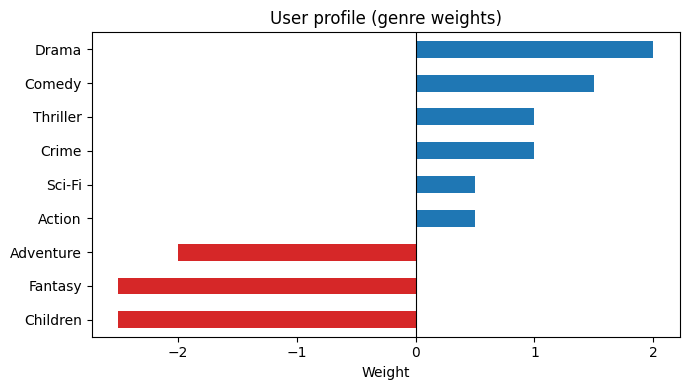

In [14]:
# Plot only the genres that actually received a weight
profile_to_plot = userProfile[userProfile != 0].sort_values()
profile_to_plot.plot(kind='barh', figsize=(7, 4),
                     color=['tab:red' if v < 0 else 'tab:blue' for v in profile_to_plot])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('User profile (genre weights)')
plt.xlabel('Weight')
plt.tight_layout()
plt.savefig('figures/result.png', dpi=150, bbox_inches='tight')
plt.show()

Now, we have the weights for every one of the user's preferences. This is known as the User Profile. Using this, we can recommend movies that satisfy the user's preferences.

Let's start by extracting the genre table from the original dataframe:

In [15]:
# Now let's get the genres of every movie, indexed by movieId so results map back to movies
genreTable = moviesWithGenres_df.set_index('movieId')[genre_cols]
genreTable.head()

,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
movieId,,,,,,,,,,,,,,,,,,,
1,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
5,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [16]:
genreTable.shape

(34208, 19)

#### Weight the genres by how rare they are (IDF)

Some genres appear on thousands of movies (*Drama*, *Comedy*) and say little about taste; rare ones (*Film-Noir*, *Western*) are much more informative. **Inverse Document Frequency (IDF)**, the "IDF" in TF-IDF, captures this: `idf = log((1 + N) / (1 + df)) + 1`, where `N` is the number of movies and `df` is how many movies have that genre. This is the same smoothed formula scikit-learn's `TfidfTransformer` uses. We multiply both the movie vectors and the user profile by these weights.

In [17]:
# N = number of movies, df = number of movies that have each genre
N = len(genreTable)
df = genreTable.sum(axis=0)

# Smoothed IDF: rare genres get bigger weights, common genres smaller ones
idf = np.log((1 + N) / (1 + df)) + 1

# Apply the weights to every movie and to the user profile
weightedGenreTable = genreTable * idf
weightedUserProfile = userProfile * idf

idf.sort_values(ascending=False).round(2)

IMAX           6.16
Film-Noir      5.61
Western        4.78
Musical        4.48
War            4.24
Animation      4.20
Children       4.06
Fantasy        4.01
Mystery        3.92
Sci-Fi         3.76
Adventure      3.52
Documentary    3.42
Horror         3.32
Crime          3.29
Action         3.04
Romance        2.95
Thriller       2.86
Comedy         2.22
Drama          1.77
dtype: float64

With the input's profile and the complete list of movies and their genres in hand, we're going to score every movie against the profile and recommend the top twenty movies that most satisfy it.

**Improvement – cosine similarity:** the original weighted average (`(genreTable*userProfile).sum(axis=1) / userProfile.sum()`) favours movies that simply list many genres, and it breaks down once the profile has negative weights (the denominator can be zero or negative). Cosine similarity measures the *angle* between the movie's genre vector and the profile: 1 means a perfect match, 0 means unrelated and negative values mean the movie leans toward genres the user dislikes.

In [18]:
# cosine_similarity expects 2-D inputs: all movies (n x genres) vs. one profile (1 x genres)
scores = cosine_similarity(weightedGenreTable.values, weightedUserProfile.values.reshape(1, -1))

# Turn the result back into a Series indexed by movieId
recommendationTable_df = pd.Series(scores.ravel(), index=genreTable.index, name='score')
recommendationTable_df.head()

movieId
1   -0.691779
2   -0.911749
3    0.115216
4    0.192445
5    0.191674
Name: score, dtype: float64

Before sorting, two practical fixes:
* **Remove movies the user already rated.** Recommending *Pulp Fiction* to someone who just rated it is useless.
* **Break ties.** Many movies share exactly the same genres, so they get exactly the same score. We use how many ratings each movie has in `ratings_df` as a secondary sort key, so well-known movies come first within a tie. The score itself is still purely content-based.

In [19]:
# Drop the movies the user has already seen
recommendationTable_df = recommendationTable_df.drop(inputMovies['movieId'], errors='ignore')

# Number of ratings per movie (popularity), used only as a tie-breaker
popularity = ratings_df.groupby('movieId').size().rename('num_ratings')

# Put score and popularity together, then sort by score first and popularity second
recommendationTable_df = (
    recommendationTable_df.to_frame()
    .join(popularity)
    .fillna({'num_ratings': 0})
    .astype({'num_ratings': int})
    .sort_values(['score', 'num_ratings'], ascending=False)
)
# Just a peek at the values
recommendationTable_df.head()

,score,num_ratings
movieId,,
608,0.362158,8295
57669,0.362158,1138
6003,0.362158,548
1034,0.362158,253
3266,0.362158,247


Now here's the recommendation table!

We use `reindex` with the top-20 ids so the movies come out **in ranking order**. The original `isin(...)` filter returned them in the dataframe's own order and dropped the scores.

In [20]:
# The final recommendation table: top 20 movies with their score, in ranking order
top20 = recommendationTable_df.head(20)
(movies_df.set_index('movieId')
          .reindex(top20.index)
          .join(top20)
          .reset_index())

,movieId,title,genres,year,score,num_ratings
0,608,Fargo,"[Comedy, Crime, Drama, Thriller]",1996,0.362158,8295
1,57669,In Bruges,"[Comedy, Crime, Drama, Thriller]",2008,0.362158,1138
2,6003,Confessions of a Dangerous Mind,"[Comedy, Crime, Drama, Thriller]",2002,0.362158,548
3,1034,Freeway,"[Comedy, Crime, Drama, Thriller]",1996,0.362158,253
4,3266,Man Bites Dog (C'est arrivé près de chez vous),"[Comedy, Crime, Drama, Thriller]",1992,0.362158,247
5,71211,"Informant!, The","[Comedy, Crime, Drama, Thriller]",2009,0.362158,165
6,75813,Leaves of Grass,"[Comedy, Crime, Drama, Thriller]",2009,0.362158,58
7,6705,Party Monster,"[Comedy, Crime, Drama, Thriller]",2003,0.362158,56
8,4242,Beautiful Creatures,"[Comedy, Crime, Drama, Thriller]",2000,0.362158,40
9,42900,Cul-de-sac,"[Comedy, Crime, Drama, Thriller]",1966,0.362158,29


### Advantages and Disadvantages of Content-Based Filtering

##### Advantages

*   Learns user's preferences
*   Highly personalized for the user
*   Works for new movies with no ratings yet, as long as their genres are known (no "item cold-start" problem)
*   Easy to explain: "recommended because you like Crime and Thriller"

##### Disadvantages

*   Doesn't take into account what others think of the item, so low quality item recommendations might happen
*   Extracting data is not always intuitive
*   Determining what characteristics of the item the user dislikes or likes is not always obvious
*   Recommendations stay close to what the user already watched (little diversity or surprise)
*   Genres alone are a coarse description. Richer content-based systems also use tags, plot summaries (TF-IDF on text, or sentence embeddings), cast and director, and often combine this with collaborative filtering in a *hybrid* recommender

### What changed compared to the original notebook

| Step | Original | Fixed / updated |
|---|---|---|
| Year column | Removed the year from the title *before* extracting it → `AttributeError` | Extract first, then remove; raw-string regexes; `Int64` dtype |
| One-hot encoding | `iterrows()` loop + `fillna(0)` (slow, and also filled missing years with 0) | `MultiLabelBinarizer`, vectorized; `(no genres listed)` dropped |
| Dropping columns | `drop('col', 1)` → `TypeError` in pandas ≥ 2.0 | `drop(columns=...)` or select `genre_cols` directly |
| Matching input titles | Implicit merge; empty result because titles still had years | Explicit, case-insensitive merge; unknown titles are reported |
| Ratings ↔ genres | Relied on two separate tables being in the same row order | Ratings merged onto the genre rows |
| User profile | Raw ratings (a 2★ movie still *boosted* its genres) | Mean-centered ratings (likes positive, dislikes negative) |
| Genre weighting | All genres equal | IDF weighting: rare genres count more |
| Scoring | Weighted average | Cosine similarity |
| Results | Included already-watched movies; ties in arbitrary order; `isin` lost the ranking | Watched movies removed; popularity tie-break; ranked output with scores |
| Last cell | Missing `#` → `SyntaxError` | Fixed |
| Unused imports | `from math import sqrt` | Removed; scikit-learn and `pathlib` added |